In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
#loading the data
data = pd.read_excel(r"C:\Users\user\OneDrive\Documents\ZION TECH HUB CAPSTONE\ICU_Sepsis_Patient_Summary.xlsx")
data.head()

,patient_id,age,gender,los_hours,developed_sepsis,sepsis_onset_hour
0,ICU0001,58,Female,66,1,33.0
1,ICU0002,41,Female,50,1,44.0
2,ICU0003,57,Male,38,0,NaN
3,ICU0004,79,Female,28,0,NaN
4,ICU0005,60,Male,49,1,38.0


In [3]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   patient_id         180 non-null    object 
 1   age                180 non-null    int64  
 2   gender             180 non-null    object 
 3   los_hours          180 non-null    int64  
 4   developed_sepsis   180 non-null    int64  
 5   sepsis_onset_hour  50 non-null     float64
dtypes: float64(1), int64(3), object(2)
memory usage: 8.6+ KB


In [4]:
data.describe()

,age,los_hours,developed_sepsis,sepsis_onset_hour
count,180.000000,180.000000,180.000000,50.000000
mean,57.255556,40.238889,0.277778,21.200000
std,16.778252,17.304814,0.449153,12.600615
min,18.000000,12.000000,0.000000,6.000000
25%,45.750000,25.000000,0.000000,11.000000
50%,58.000000,39.000000,0.000000,17.500000
75%,68.250000,55.250000,1.000000,30.750000
max,95.000000,72.000000,1.000000,51.000000


In [5]:
data['sepsis_onset_hour'].values

array([33., 44., nan, nan, 38., nan, nan, nan, nan,  8., nan, nan, nan,
       16., nan, nan, nan, nan,  8., nan, nan, nan, 20., 42., nan, nan,
       33., nan, nan, nan, nan, nan, 36., nan, 31., nan, nan, 14., 10.,
       nan, nan, nan, 44., nan, nan, nan, nan, nan, 16., nan, nan, nan,
       nan, nan, nan, nan, 30., nan, 51., 21., 34., 10., 49., 19., nan,
        7., nan, nan, nan, nan, 25., nan, 11., nan, nan, nan, 18., nan,
       nan, nan, nan, nan, nan, 11., 17., nan, nan, nan, nan, nan,  9.,
       16., nan, nan, nan, nan, nan, nan, 27., nan, nan, nan, nan, nan,
       17., nan, nan, nan, nan, nan, nan, nan, nan, nan, nan, 10., nan,
       nan, 12., nan, nan, nan, nan, nan, nan, nan, 17., nan, nan, nan,
       nan, nan, nan,  9., 23., 20., 46., 20., nan, nan, nan,  6., nan,
       19., nan, nan, nan, 33., nan, nan, nan, 19., nan, nan, nan, nan,
       nan, nan, nan, nan, nan, nan, nan, 10.,  9.,  6., nan, nan, nan,
       13., nan, nan, nan, 12., nan, 11., nan, nan, nan, nan])

In [6]:
data[data['los_hours'] < data['sepsis_onset_hour']]

,patient_id,age,gender,los_hours,developed_sepsis,sepsis_onset_hour


##### A patient's LOS is always greater than sepsis onset hour. Therefore, sepsis onset hour column means the nth hour within the patient's LOS that the patient developed sepsis.

In [7]:
data.isnull().sum()

patient_id             0
age                    0
gender                 0
los_hours              0
developed_sepsis       0
sepsis_onset_hour    130
dtype: int64

In [8]:
missing = data[data['sepsis_onset_hour'].isnull()]
missing[missing['developed_sepsis'] != 0]

,patient_id,age,gender,los_hours,developed_sepsis,sepsis_onset_hour


##### All patients with missing sepsis onset hour did not develop sepsis. This is expected and normal. Hence sepsis onset hour NaN values will be left as is.

### MODEL DEVELOPMENT

##### DATA CLEANING AND PREPROCESSING

In [9]:
#loading the second table for model building
data_cli = pd.read_excel(r"C:\Users\user\OneDrive\Documents\ZION TECH HUB CAPSTONE\ICU_Sepsis_Patient_Data.xlsx")

In [10]:
data_cli.head()

,patient_id,age,gender,los_hours,heart_rate_bpm,systolic_bp_mmhg,respiratory_rate_bpm,temperature_c,spo2_percent,wbc_10e9_l,lactate_mmol_l,creatinine_mg_dl,platelets_10e9_l,gcs_score,urine_output_ml_kg_hr,antibiotics_administered,vasopressors_administered,mechanical_ventilation
0,ICU0001,58,Female,66,85.7,98.3,22.5,37.06,94.8,10.17,1.75,1.29,179.5,14,1.30,1,0,0
1,ICU0002,41,Female,50,77.7,129.0,22.6,37.15,96.2,7.80,1.34,0.62,258.5,13,1.17,0,0,0
2,ICU0003,57,Male,38,73.2,129.6,12.2,36.66,98.8,4.90,1.00,1.33,251.8,13,NaN,0,0,0
3,ICU0004,79,Female,28,80.1,119.0,12.2,36.42,96.7,9.31,1.37,0.73,257.1,15,0.54,0,0,0
4,ICU0005,60,Male,49,80.0,118.8,18.4,36.60,98.5,7.70,1.46,1.47,218.3,15,1.43,0,0,0


In [11]:
data_cli.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 18 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   patient_id                 180 non-null    object 
 1   age                        180 non-null    int64  
 2   gender                     180 non-null    object 
 3   los_hours                  180 non-null    int64  
 4   heart_rate_bpm             180 non-null    float64
 5   systolic_bp_mmhg           180 non-null    float64
 6   respiratory_rate_bpm       180 non-null    float64
 7   temperature_c              176 non-null    float64
 8   spo2_percent               180 non-null    float64
 9   wbc_10e9_l                 174 non-null    float64
 10  lactate_mmol_l             172 non-null    float64
 11  creatinine_mg_dl           175 non-null    float64
 12  platelets_10e9_l           180 non-null    float64
 13  gcs_score                  180 non-null    int64  

In [12]:
data_cli.describe()

,age,los_hours,heart_rate_bpm,systolic_bp_mmhg,respiratory_rate_bpm,temperature_c,spo2_percent,wbc_10e9_l,lactate_mmol_l,creatinine_mg_dl,platelets_10e9_l,gcs_score,urine_output_ml_kg_hr,antibiotics_administered,vasopressors_administered,mechanical_ventilation
count,180.000000,180.000000,180.000000,180.000000,180.000000,176.000000,180.000000,174.000000,172.000000,175.000000,180.000000,180.000000,173.000000,180.000000,180.000000,180.000000
mean,57.255556,40.238889,82.485000,123.247222,17.758889,36.869148,96.781667,8.184023,1.395523,0.997543,231.437778,14.466667,1.241792,0.288889,0.133333,0.222222
std,16.778252,17.304814,8.674064,12.673164,3.727383,0.273366,1.501004,2.355393,0.490254,0.362347,36.248611,0.800838,0.288613,0.454510,0.340883,0.416899
min,18.000000,12.000000,62.700000,88.000000,9.000000,36.120000,92.800000,2.500000,0.500000,0.350000,133.500000,11.000000,0.370000,0.000000,0.000000,0.000000
25%,45.750000,25.000000,76.450000,113.475000,15.000000,36.680000,95.800000,6.507500,1.025000,0.730000,209.575000,14.000000,1.070000,0.000000,0.000000,0.000000
50%,58.000000,39.000000,81.700000,123.750000,18.150000,36.890000,96.900000,8.335000,1.385000,0.990000,230.800000,15.000000,1.270000,0.000000,0.000000,0.000000
75%,68.250000,55.250000,87.525000,130.500000,20.425000,37.060000,97.900000,9.752500,1.730000,1.255000,255.975000,15.000000,1.440000,1.000000,0.000000,0.000000
max,95.000000,72.000000,108.200000,157.200000,26.400000,37.550000,100.000000,14.990000,2.580000,2.020000,331.700000,15.000000,1.900000,1.000000,1.000000,1.000000


In [13]:
data_cli.describe(include='object')

,patient_id,gender
count,180,180
unique,180,2
top,ICU0001,Female
freq,1,93


In [14]:
data_cli.isnull().sum()

patient_id                   0
age                          0
gender                       0
los_hours                    0
heart_rate_bpm               0
systolic_bp_mmhg             0
respiratory_rate_bpm         0
temperature_c                4
spo2_percent                 0
wbc_10e9_l                   6
lactate_mmol_l               8
creatinine_mg_dl             5
platelets_10e9_l             0
gcs_score                    0
urine_output_ml_kg_hr        7
antibiotics_administered     0
vasopressors_administered    0
mechanical_ventilation       0
dtype: int64

##### For the sake of model building, the missing values will be filled using the values of their nearest neighbours (KNN Imputer)

In [15]:
#merging the two dataframes into a master df
data_cli_drop = data_cli.drop(columns=['age', 'gender', 'los_hours'])
master_df = data.merge(data_cli_drop, on='patient_id', how='inner')
master_df.head()

,patient_id,age,gender,los_hours,developed_sepsis,sepsis_onset_hour,heart_rate_bpm,systolic_bp_mmhg,respiratory_rate_bpm,temperature_c,spo2_percent,wbc_10e9_l,lactate_mmol_l,creatinine_mg_dl,platelets_10e9_l,gcs_score,urine_output_ml_kg_hr,antibiotics_administered,vasopressors_administered,mechanical_ventilation
0,ICU0001,58,Female,66,1,33.0,85.7,98.3,22.5,37.06,94.8,10.17,1.75,1.29,179.5,14,1.30,1,0,0
1,ICU0002,41,Female,50,1,44.0,77.7,129.0,22.6,37.15,96.2,7.80,1.34,0.62,258.5,13,1.17,0,0,0
2,ICU0003,57,Male,38,0,NaN,73.2,129.6,12.2,36.66,98.8,4.90,1.00,1.33,251.8,13,NaN,0,0,0
3,ICU0004,79,Female,28,0,NaN,80.1,119.0,12.2,36.42,96.7,9.31,1.37,0.73,257.1,15,0.54,0,0,0
4,ICU0005,60,Male,49,1,38.0,80.0,118.8,18.4,36.60,98.5,7.70,1.46,1.47,218.3,15,1.43,0,0,0


In [16]:
master_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 180 entries, 0 to 179
Data columns (total 20 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   patient_id                 180 non-null    object 
 1   age                        180 non-null    int64  
 2   gender                     180 non-null    object 
 3   los_hours                  180 non-null    int64  
 4   developed_sepsis           180 non-null    int64  
 5   sepsis_onset_hour          50 non-null     float64
 6   heart_rate_bpm             180 non-null    float64
 7   systolic_bp_mmhg           180 non-null    float64
 8   respiratory_rate_bpm       180 non-null    float64
 9   temperature_c              176 non-null    float64
 10  spo2_percent               180 non-null    float64
 11  wbc_10e9_l                 174 non-null    float64
 12  lactate_mmol_l             172 non-null    float64
 13  creatinine_mg_dl           175 non-null    float64

In [17]:
#defining features and target
x = master_df.drop(columns=['patient_id', 'los_hours', 'developed_sepsis', 'sepsis_onset_hour', 'antibiotics_administered', 'vasopressors_administered', 'mechanical_ventilation'])
y = master_df['developed_sepsis']

In [18]:
#one-hot encoding categorical variables
x_encoded = pd.get_dummies(x, columns=['gender'], drop_first=True)

In [19]:
#splitting the train and test data with y stratification due to imbalanced cohort data
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x_encoded, y, test_size=0.2, random_state=42, stratify=y)

In [20]:
# imputing missing values using KNN imputer
from sklearn.impute import KNNImputer
imputer = KNNImputer(n_neighbors=5)
x_train_imputed = pd.DataFrame(imputer.fit_transform(x_train), columns=x_encoded.columns)
x_test_imputed = pd.DataFrame(imputer.transform(x_test), columns=x_encoded.columns)

In [21]:
#scaling the features for logistic regression
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
x_train_scaled = scaler.fit_transform(x_train_imputed)
x_test_scaled = scaler.transform(x_test_imputed)

##### MODEL TRAINING

In [22]:
#building the models
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report, confusion_matrix
log = LogisticRegression(random_state=42, max_iter=1000)
dec = DecisionTreeClassifier(random_state=42, max_depth=5)
ran = RandomForestClassifier(n_estimators=100, random_state=42)

In [23]:
#training the models (random forest and decision tree do not use scaled data)
log.fit(x_train_scaled, y_train)
dec.fit(x_train_imputed, y_train)
ran.fit(x_train_imputed, y_train)

RandomForestClassifier(random_state=42)

##### PREDICTION AND EVALUATION

In [24]:
#making predictions (logistic regression)
y_pred_log = log.predict(x_test_scaled)
y_prob_log = log.predict_proba(x_test_scaled)[:, 1]

#decision tree
y_pred_dec = dec.predict(x_test_imputed)
y_prob_dec = dec.predict_proba(x_test_imputed)[:, 1]

#random forest
y_pred_ran = ran.predict(x_test_imputed)
y_prob_ran = ran.predict_proba(x_test_imputed)[:, 1]

In [25]:
#model evaluation (logistic regression)
print(f"Accuracy: {accuracy_score(y_test, y_pred_log):.3f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob_log):.3f}")
print("Classification Report")
print(classification_report(y_test, y_pred_log))
print("Confusion Matrix")
print(confusion_matrix(y_test, y_pred_log))

Accuracy: 0.694
ROC-AUC: 0.654
Classification Report
              precision    recall  f1-score   support

           0       0.73      0.92      0.81        26
           1       0.33      0.10      0.15        10

    accuracy                           0.69        36
   macro avg       0.53      0.51      0.48        36
weighted avg       0.62      0.69      0.63        36

Confusion Matrix
[[24  2]
 [ 9  1]]


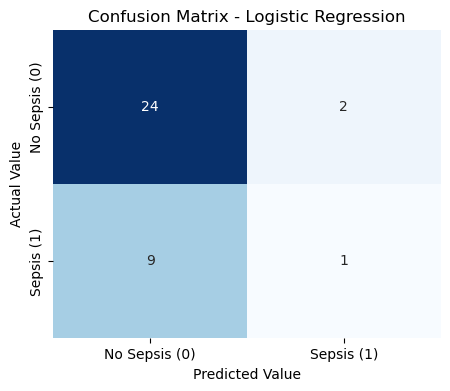

In [26]:
conf_matrix = confusion_matrix(y_test, y_pred_log)
plt.figure(figsize=(5,4))
sns.heatmap(conf_matrix,annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=['No Sepsis (0)', 'Sepsis (1)'], yticklabels=['No Sepsis (0)', 'Sepsis (1)'])
plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted Value')
plt.ylabel('Actual Value')
plt.show()

In [27]:
#model evaluation (decision tree)
print(f"Accuracy: {accuracy_score(y_test, y_pred_dec):.3f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob_dec):.3f}")
print("Classification Report")
print(classification_report(y_test, y_pred_dec))
print("Confusion Matrix")
print(confusion_matrix(y_test, y_pred_dec))

Accuracy: 0.667
ROC-AUC: 0.525
Classification Report
              precision    recall  f1-score   support

           0       0.73      0.85      0.79        26
           1       0.33      0.20      0.25        10

    accuracy                           0.67        36
   macro avg       0.53      0.52      0.52        36
weighted avg       0.62      0.67      0.64        36

Confusion Matrix
[[22  4]
 [ 8  2]]


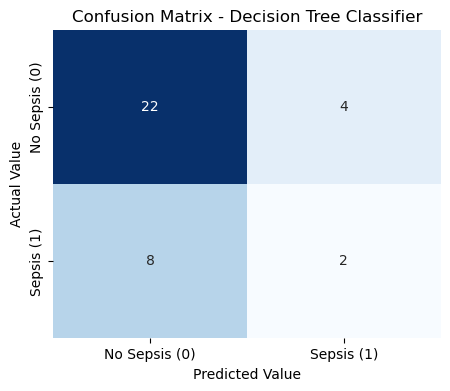

In [28]:
conf_matrix = confusion_matrix(y_test, y_pred_dec)
plt.figure(figsize=(5,4))
sns.heatmap(conf_matrix,annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=['No Sepsis (0)', 'Sepsis (1)'], yticklabels=['No Sepsis (0)', 'Sepsis (1)'])
plt.title('Confusion Matrix - Decision Tree Classifier')
plt.xlabel('Predicted Value')
plt.ylabel('Actual Value')
plt.show()

In [29]:
#model evaluation (random forest)
print(f"Accuracy: {accuracy_score(y_test, y_pred_ran):.3f}")
print(f"ROC-AUC: {roc_auc_score(y_test, y_prob_ran):.3f}")
print("Classification Report")
print(classification_report(y_test, y_pred_ran))
print("Confusion Matrix")
print(confusion_matrix(y_test, y_pred_ran))

Accuracy: 0.722
ROC-AUC: 0.752
Classification Report
              precision    recall  f1-score   support

           0       0.74      0.96      0.83        26
           1       0.50      0.10      0.17        10

    accuracy                           0.72        36
   macro avg       0.62      0.53      0.50        36
weighted avg       0.67      0.72      0.65        36

Confusion Matrix
[[25  1]
 [ 9  1]]


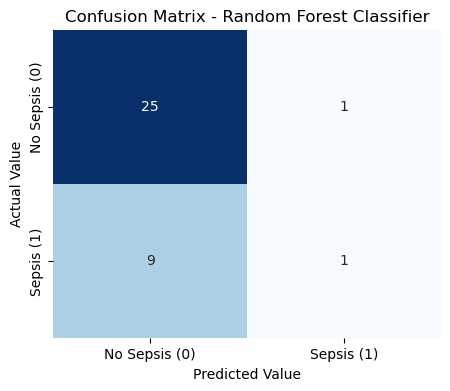

In [30]:
# plotting the confusion matrix
conf_matrix = confusion_matrix(y_test, y_pred_ran)
plt.figure(figsize=(5,4))
sns.heatmap(conf_matrix,annot=True, fmt='d', cmap='Blues', cbar=False, xticklabels=['No Sepsis (0)', 'Sepsis (1)'], yticklabels=['No Sepsis (0)', 'Sepsis (1)'])
plt.title('Confusion Matrix - Random Forest Classifier')
plt.xlabel('Predicted Value')
plt.ylabel('Actual Value')
plt.savefig(r'C:\Users\user\OneDrive\Documents\ZION TECH HUB CAPSTONE\rf_confusion_matrix.png', dpi=300, bbox_inches='tight')
plt.show()

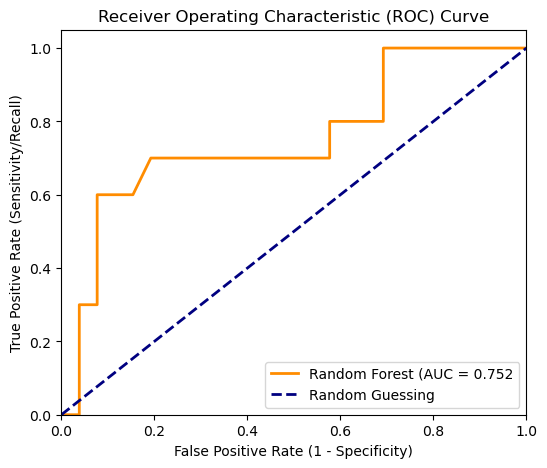

In [31]:
#plotting the ROC-AUC Curve
from sklearn.metrics import roc_curve
roc_auc = roc_auc_score(y_test, y_prob_ran)
fpr, tpr, thresholds = roc_curve(y_test, y_prob_ran)
plt.figure(figsize=(6,5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Random Forest (AUC = {roc_auc:.3f}')
plt.plot([0,1], [0,1], color='navy', lw=2, linestyle='--', label='Random Guessing')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate (1 - Specificity)')
plt.ylabel('True Positive Rate (Sensitivity/Recall)')
plt.title('Receiver Operating Characteristic (ROC) Curve')
plt.legend(loc='lower right')
plt.savefig(r'C:\Users\user\OneDrive\Documents\ZION TECH HUB CAPSTONE\rf_roc_curve.png', dpi=300, bbox_inches='tight')
plt.show()